In [1]:
pip install tensorflow scikit-learn pandas matplotlib seaborn numpy pillow 

Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 620.4 MB 41 kB/s               
     |████████████████████████████████| 4.6 MB 120.5 MB/s            
     |████████████████████████████████| 230 kB 140.6 MB/s            
     |████████████████████████████████| 24.5 MB 102.5 MB/s            
     |████████████████████████████████| 71 kB 69 kB/s              
     |████████████████████████████████| 5.0 MB 134.3 MB/s            
     |████████████████████████████████| 5.5 MB 112.7 MB/s            
     |████████████████████████████████| 323 kB 144.1 MB/s            
     |████████████████████████████████| 1.4 MB 94.8 MB/s            
     |████████████████████████████████| 6.8 MB 71.3 MB/s            
     |████████████████████████████████| 135 kB 122.5 MB/s            
     |████████████████████████████████| 57 kB 2.4 MB/s             
     |████████████████████████████████| 452 kB 110.6 MB/s            
     |█████████

In [1]:
import os
import random
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

2026-10-11 17:52:23.726233: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-11 17:52:23.769863: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


TensorFlow version: 2.20.0
GPU available: []


2026-10-11 17:52:24.777655: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-11 17:52:24.912953: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [3]:
from pathlib import Path

extract_path = Path("data/raw")

for item in extract_path.iterdir():
    if item.is_dir():
        print(f"📁 {item.name}: {sum(1 for p in item.rglob('*') if p.is_file())} files")
    else:
        print(f"📄 {item.name}")

📁 FDM-3D-Printing-Defect-Dataset: 1912 files


In [4]:
from pathlib import Path

DATA_ROOT = Path("data/raw")

for path in DATA_ROOT.rglob("*"):
    if path.is_dir():
        image_count = sum(
            1 for f in path.iterdir()
            if f.is_file() and f.suffix.lower()
            in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
        )
        if image_count > 0:
            print(f"{path}  -->  {image_count} images")

data/raw/FDM-3D-Printing-Defect-Dataset/data/Cracking  -->  472 images
data/raw/FDM-3D-Printing-Defect-Dataset/data/Layer_shifting  -->  364 images
data/raw/FDM-3D-Printing-Defect-Dataset/data/Off_platform  -->  91 images
data/raw/FDM-3D-Printing-Defect-Dataset/data/Stringing  -->  447 images
data/raw/FDM-3D-Printing-Defect-Dataset/data/Warping  -->  538 images


In [5]:
from tensorflow.keras.applications.vgg16 import (
    VGG16,
    preprocess_input
)
from tensorflow.keras import layers, models

In [6]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    "data/split/train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    "data/split/val",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    "data/split/test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

CLASS_NAMES = train_ds.class_names
NUM_CLASSES = len(CLASS_NAMES)

print(CLASS_NAMES)

Found 1335 files belonging to 5 classes.
Found 288 files belonging to 5 classes.
Found 289 files belonging to 5 classes.
['Cracking', 'Layer_shifting', 'Off_platform', 'Stringing', 'Warping']


In [7]:
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras import layers, models

base_model = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3))
x = layers.Lambda(preprocess_input)(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,847,301 (56.64 MB)

 Trainable params: 132,613 (518.02 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [8]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stop]
)

Epoch 1/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 11s 251ms/step - accuracy: 0.2800 - loss: 5.1490 - val_accuracy: 0.5903 - val_loss: 1.3436
Epoch 2/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 11s 249ms/step - accuracy: 0.5224 - loss: 2.2632 - val_accuracy: 0.7465 - val_loss: 0.8152
Epoch 3/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 10s 242ms/step - accuracy: 0.6403 - loss: 1.3871 - val_accuracy: 0.8090 - val_loss: 0.5469
Epoch 4/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 11s 249ms/step - accuracy: 0.7302 - loss: 0.8393 - val_accuracy: 0.8646 - val_loss: 0.3651
Epoch 5/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 11s 252ms/step - accuracy: 0.7976 - loss: 0.6065 - val_accuracy: 0.9062 - val_loss: 0.2548
Epoch 6/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 11s 246ms/step - accuracy: 0.8505 - loss: 0.4815 - val_accuracy: 0.9236 - val_loss: 0.2150
Epoch 7/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 10s 242ms/step - accuracy: 0.8686 - loss: 0.3751 - val_accuracy: 0.9479 - val_loss: 0.1779
Epoch 8/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 11s 246ms/step - accuracy: 0.8839 - loss: 0.3021 - val_accu

In [9]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("Test Loss:", round(test_loss, 4))

10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 161ms/step - accuracy: 0.9880 - loss: 0.0592
Test Accuracy: 98.96 %
Test Loss: 0.05


In [10]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("Test Loss:", round(test_loss, 4))

10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 159ms/step - accuracy: 0.9880 - loss: 0.0592
Test Accuracy: 98.96 %
Test Loss: 0.05


In [11]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

y_pred = np.argmax(model.predict(test_ds), axis=1)

print("Predictions completed!")

2026-10-11 17:56:42.012887: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 165ms/step
Predictions completed!


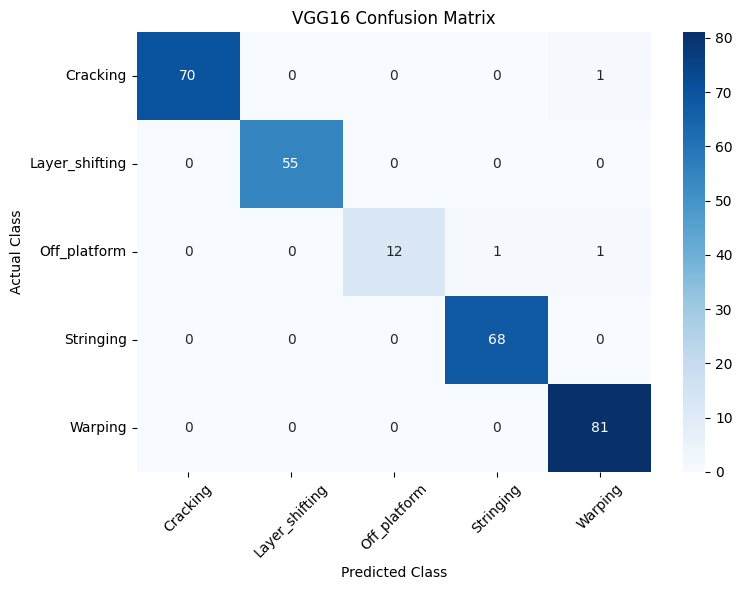

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("VGG16 Confusion Matrix")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

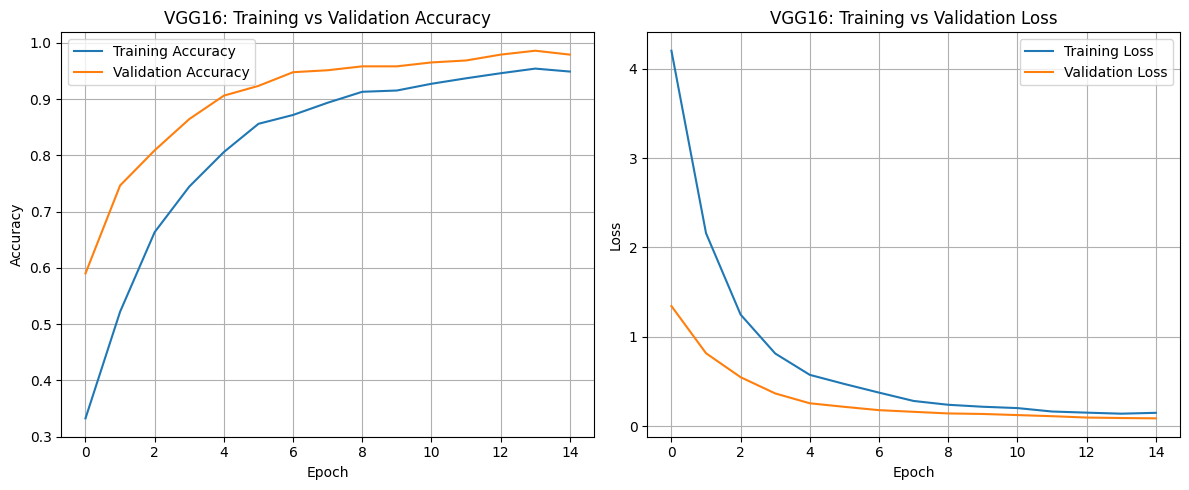

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Accuracy comparison
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("VGG16: Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss comparison
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("VGG16: Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [14]:
train_acc = history.history["accuracy"][-1]
val_acc = history.history["val_accuracy"][-1]

train_loss = history.history["loss"][-1]
val_loss = history.history["val_loss"][-1]

print("Training Accuracy:", round(train_acc * 100, 2), "%")
print("Validation Accuracy:", round(val_acc * 100, 2), "%")
print("Accuracy Gap:", round((train_acc - val_acc) * 100, 2), "percentage points")

print("Training Loss:", round(train_loss, 4))
print("Validation Loss:", round(val_loss, 4))

Training Accuracy: 94.91 %
Validation Accuracy: 97.92 %
Accuracy Gap: -3.01 percentage points
Training Loss: 0.148
Validation Loss: 0.0862


In [15]:
if train_loss < val_loss and (val_acc < train_acc - 0.05):
    print("Possible overfitting: training performance is notably better.")
elif val_loss > min(history.history["val_loss"]) * 1.2:
    print("Validation loss has risen notably from its minimum. Check the loss plot.")
else:
    print("No clear overfitting signal from this simple check.")

No clear overfitting signal from this simple check.


In [16]:
best_epoch = history.history["val_loss"].index(
    min(history.history["val_loss"])
) + 1

print("Best Epoch:", best_epoch)
print("Best Validation Loss:", round(min(history.history["val_loss"]), 4))
print(
    "Validation Accuracy at Best Epoch:",
    round(history.history["val_accuracy"][best_epoch - 1] * 100, 2),
    "%"
)

Best Epoch: 15
Best Validation Loss: 0.0862
Validation Accuracy at Best Epoch: 97.92 %


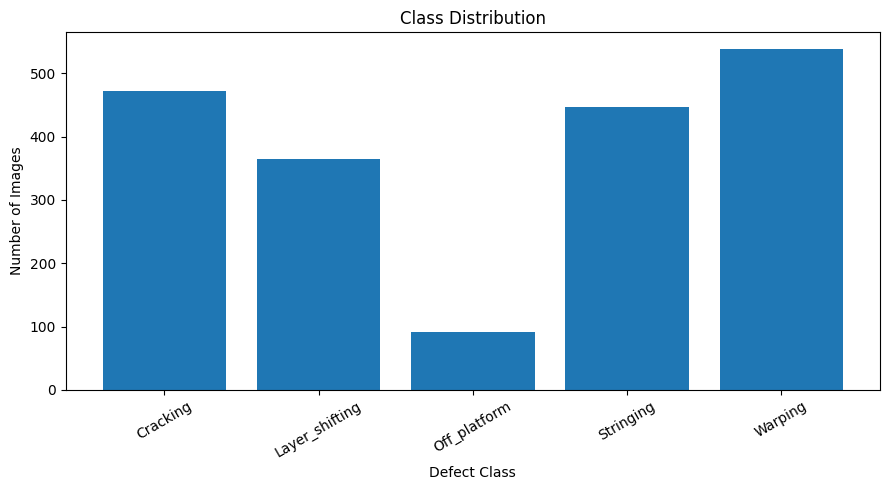

{'Cracking': 472, 'Layer_shifting': 364, 'Off_platform': 91, 'Stringing': 447, 'Warping': 538}


In [17]:
import matplotlib.pyplot as plt
from pathlib import Path

DATA_ROOT = Path("data/raw/FDM-3D-Printing-Defect-Dataset/data")

class_counts = {
    folder.name: len([
        f for f in folder.iterdir()
        if f.is_file() and f.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]
    ])
    for folder in DATA_ROOT.iterdir()
    if folder.is_dir()
}

plt.figure(figsize=(9, 5))
plt.bar(class_counts.keys(), class_counts.values())
plt.title("Class Distribution")
plt.xlabel("Defect Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

print(class_counts)

In [18]:
import numpy as np
from sklearn.metrics import classification_report

y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

y_pred = np.argmax(model.predict(test_ds), axis=1)

print(classification_report(
    y_true,
    y_pred,
    labels=range(len(CLASS_NAMES)),
    target_names=CLASS_NAMES,
    zero_division=0
))

2026-10-11 17:59:11.367261: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 161ms/step
                precision    recall  f1-score   support

      Cracking       1.00      0.99      0.99        71
Layer_shifting       1.00      1.00      1.00        55
  Off_platform       1.00      0.86      0.92        14
     Stringing       0.99      1.00      0.99        68
       Warping       0.98      1.00      0.99        81

      accuracy                           0.99       289
     macro avg       0.99      0.97      0.98       289
  weighted avg       0.99      0.99      0.99       289



In [ ]:
model.save("model.keras")
